# Pipeline complet — Classification supervisée : échantillons d'apprentissage / validation / test
Même logique que `02_CS_pipeline_complet.ipynb`, mais **sans validation croisée** : les données sont découpées **une seule fois** (de façon **stratifiée** : même proportion de Y=1 partout) en trois échantillons.

| Échantillon | Rôle |
|---|---|
| **Apprentissage** | ajuste les modèles |
| **Validation** | choisit les hyperparamètres (C des méthodes pénalisées, nombre d'itérations du boosting) et sert d'échantillon d'early stopping. Critère de choix : la **log-vraisemblance négative** (log-loss) |
| **Test** | évalue **une seule fois** le modèle final : estimation honnête de la performance |

**Modèles comparés** : `log`, `BIC` / `AIC` (forward, sur l'apprentissage), `ridge`, `lasso`, `elast`, `foret`, `gbm1`, `gbm2`, `cat`.

**Étapes** : 1. configuration → 2. découpage et ajustement de tous les modèles, pour chaque jeu de variables → 3. résultats (indicateurs avec intervalle de confiance sur l'AUC, courbes ROC, hyperparamètres, courbes de validation) → 4. export.

**Prérequis** : `01_preparationCS.ipynb` exécuté (`dfbase.csv`, `dfpoly.csv`...) ; `logistic_step_sk.py` dans le même dossier ; `catboost` optionnel.

> **Précautions** : avec un seul découpage, les résultats dépendent du tirage (changer `GRAINE_SPLIT`) et l'échantillon de test est **petit** (une centaine d'observations pour SAheart) : l'intervalle de confiance de l'AUC est large. Des méthodes dont les intervalles se recouvrent ne sont pas réellement départageables. Les indicateurs de validation sont **optimistes** (ils ont servi à régler les modèles) : c'est le test qui fait foi.

## 1. Configuration

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn.metrics as sklm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None
    print("catboost non installé (pip install catboost) : la méthode 'cat' sera ignorée")

try:
    import logistic_step_sk as lss
except ImportError:
    lss = None
    print("logistic_step_sk.py introuvable : BIC et AIC seront ignorés")

# ← Paramètres à modifier
JEUX = ["base"]          # jeux de variables à comparer : "base", "poly", "inter", "full" (un ou plusieurs)
TAILLE_TEST = 0.2        # part de l'échantillon de test
TAILLE_VAL = 0.2         # part de l'échantillon de validation (le reste = apprentissage)
GRAINE_SPLIT = 123       # graine du découpage apprentissage / validation / test
GRAINE = 42              # graine de tous les modèles (résultats reproductibles)
CALCULER_IC = True       # BIC / AIC forward : rapide avec "base", plus long avec "inter" / "full"
CAT_EVAL_METRIC = "Accuracy"   # critère d'early stopping de CatBoost ; mêmes réglages que le pipeline CV (essayer "Logloss")
N_BOOT_IC = 1000         # rééchantillonnages pour l'intervalle de confiance de l'AUC de test
NB_C = 50                # taille de la grille de C pour les méthodes pénalisées
DOSSIER_DONNEES = "./"   # dossier des dfbase.csv, dfpoly.csv... (écrits par 01_preparationCS)
DOSSIER_SORTIE = "./"    # dossier où écrire les fichiers résultats

# Option pour tester le code rapidement : n'utilise qu'une fraction des lignes, tirées au hasard.
# Les résultats n'ont alors aucune valeur ; les fichiers sont écrits dans test_pipeline/ pour ne rien écraser.
MODE_TEST = False        # True pour activer le mode test (CatBoost utilise alors subsample=0.8 : trop peu de lignes pour 0.1)
FRACTION_TEST = 0.10     # part des lignes conservées en mode test
GRAINE_ECHANTILLON = 2025   # graine du tirage des lignes
if MODE_TEST:
    DOSSIER_SORTIE = "test_pipeline/"
    os.makedirs(DOSSIER_SORTIE, exist_ok=True)
    print(f"MODE TEST : {FRACTION_TEST:.0%} des lignes, résultats écrits dans {DOSSIER_SORTIE}")

# jeu -> (fichier de variables, fichier de probabilités de test lu par 03_analyseCS_complet avec SUFFIXE_PROB = "_test")
FICHIERS = {"base": ("dfbase.csv", "PROB_test.csv"), "poly": ("dfpoly.csv", "PROBpoly_test.csv"),
            "inter": ("dfinter.csv", "PROBinter_test.csv"), "full": ("dffull.csv", "PROBfull_test.csv")}

## 2. Découpage et ajustement de tous les modèles
Pour chaque méthode : ajustement sur l'**apprentissage**, réglage des hyperparamètres sur la **validation**, puis prédiction de P(Y=1) sur validation et test. Le test n'est utilisé que pour la prédiction finale.

In [2]:
def grille(X, y, type="lasso", ng=100):
    """Grille de valeurs C (inverse du paramètre de régularisation) adaptée à l'échelle des données,
    à partir de la plus grande valeur utile l0 (au-delà de laquelle le lasso annule tous les coefficients)."""
    Xcr = StandardScaler().fit(X).transform(X)
    l0 = np.abs(Xcr.T.dot(y - y.mean())).max() / X.shape[0]
    llc = np.linspace(0, -4, ng)
    facteur = {"lasso": 1, "ridge": 100, "enet": 2}[type]   # ridge et elastic net ont des échelles décalées
    return 1 / 0.9 / X.shape[0] / (l0 * 10 ** llc * facteur)


def comparer(jeu):
    """Ajuste toutes les méthodes sur un jeu de variables ; renvoie les probabilités de validation et de test,
    les hyperparamètres retenus, les temps de calcul et les courbes de validation."""
    don = pd.read_csv(DOSSIER_DONNEES + FICHIERS[jeu][0])
    if MODE_TEST:
        don = don.sample(frac=FRACTION_TEST, random_state=GRAINE_ECHANTILLON).sort_index()
    X = don.drop(columns=["Y"]).to_numpy()
    Y = don["Y"].to_numpy()

    idx = np.arange(len(Y))
    idx_appval, idx_test = train_test_split(idx, test_size=TAILLE_TEST, stratify=Y, random_state=GRAINE_SPLIT)
    idx_app, idx_val = train_test_split(idx_appval, test_size=TAILLE_VAL / (1 - TAILLE_TEST),
                                        stratify=Y[idx_appval], random_state=GRAINE_SPLIT)
    X_app, X_val, X_test = X[idx_app], X[idx_val], X[idx_test]
    Y_app, Y_val, Y_test = Y[idx_app], Y[idx_val], Y[idx_test]
    print(f"\n=== Jeu '{jeu}' : {X.shape[1]} variables | apprentissage {len(idx_app)} / "
          f"validation {len(idx_val)} / test {len(idx_test)} (Y=1 : {Y.mean():.1%}) ===")

    pv, pt, hyper, temps, courbes = {}, {}, {}, {}, {}

    def enregistrer(nom, proba_val, proba_test, t0, **params):
        pv[nom], pt[nom] = proba_val[:, 1], proba_test[:, 1]      # probabilité d'appartenir à la classe Y=1
        temps[nom] = time.time() - t0
        hyper.update(params)

    def logloss(proba):
        return sklm.log_loss(Y_val, proba, labels=[0, 1])

    # --- Logistique complète (sans pénalité)
    t0 = time.time()
    log = LogisticRegression(penalty=None, solver="newton-cholesky").fit(X_app, Y_app)
    enregistrer("log", log.predict_proba(X_val), log.predict_proba(X_test), t0)

    # --- Sélection forward par BIC / AIC (critère d'information sur l'apprentissage)
    if CALCULER_IC and lss is not None:
        for crit in ("bic", "aic"):
            t0 = time.time()
            choix = lss.LogisticRegressionSelectionFeatureIC(
                start=[], direction="forward", crit=crit, multi_class="auto").fit(X_app, Y_app)
            enregistrer(crit.upper(), choix.predict_proba(X_val), choix.predict_proba(X_test), t0,
                        **{f"nb_var_{crit.upper()}": len(choix.selected_features_)})

    # --- Ridge, lasso, elastic net logistiques : variables centrées-réduites sur l'apprentissage, C choisi sur la validation
    cr = StandardScaler().fit(X_app)
    Z_app, Z_val, Z_test = cr.transform(X_app), cr.transform(X_val), cr.transform(X_test)
    for nom, type_grille, kwargs in [
        ("ridge", "ridge", dict(penalty="l2", max_iter=1000)),
        ("lasso", "lasso", dict(penalty="l1", solver="saga", max_iter=2000)),
        ("elast", "enet", dict(penalty="elasticnet", solver="saga", l1_ratio=0.5, max_iter=2000)),
    ]:
        t0 = time.time()
        Cs = grille(X_app, Y_app, type_grille, ng=NB_C)
        erreurs = [logloss(LogisticRegression(C=C, random_state=GRAINE, **kwargs).fit(Z_app, Y_app).predict_proba(Z_val))
                   for C in Cs]
        C_opt = Cs[int(np.argmin(erreurs))]
        modele = LogisticRegression(C=C_opt, random_state=GRAINE, **kwargs).fit(Z_app, Y_app)
        courbes[nom] = (Cs, np.array(erreurs))
        enregistrer(nom, modele.predict_proba(Z_val), modele.predict_proba(Z_test), t0, **{f"C_{nom}": C_opt})

    # --- Forêt aléatoire
    t0 = time.time()
    foret = RandomForestClassifier(random_state=GRAINE).fit(X_app, Y_app)
    enregistrer("foret", foret.predict_proba(X_val), foret.predict_proba(X_test), t0)

    # --- Gradient boosting : le nombre d'itérations minimise le log-loss de validation
    for nom, profondeur in [("gbm1", 1), ("gbm2", 2)]:
        t0 = time.time()
        gbm = GradientBoostingClassifier(n_estimators=1000, max_depth=profondeur, learning_rate=0.1,
                                         random_state=GRAINE).fit(X_app, Y_app)
        stages_val = list(gbm.staged_predict_proba(X_val))
        stages_test = list(gbm.staged_predict_proba(X_test))
        erreurs = np.array([logloss(p) for p in stages_val])
        k = int(np.argmin(erreurs))
        courbes[nom] = (np.arange(1, len(erreurs) + 1), erreurs)
        enregistrer(nom, stages_val[k], stages_test[k], t0, **{f"nb_iter_{nom}": k + 1})

    # --- CatBoost : early stopping sur l'échantillon de validation
    if CatBoostClassifier is not None:
        t0 = time.time()
        cat = CatBoostClassifier(iterations=5000, learning_rate=0.01, subsample=(0.8 if MODE_TEST else 0.1), loss_function="Logloss",
                                 eval_metric=CAT_EVAL_METRIC, random_seed=GRAINE, verbose=0,
                                 allow_writing_files=False)
        cat.fit(X_app, Y_app, eval_set=(X_val, Y_val), early_stopping_rounds=10)
        enregistrer("cat", cat.predict_proba(X_val), cat.predict_proba(X_test), t0, nb_iter_cat=cat.get_best_iteration())

    return dict(Y_val=Y_val, Y_test=Y_test, pv=pd.DataFrame(pv), pt=pd.DataFrame(pt), hyper=hyper,
                temps=temps, courbes=courbes, tailles=(len(idx_app), len(idx_val), len(idx_test)))


resultats = {jeu: comparer(jeu) for jeu in JEUX}
for jeu, r in resultats.items():
    print(f"{jeu} : {r['pt'].shape[1]} méthodes -> {list(r['pt'].columns)}")


=== Jeu 'base' : 9 variables | apprentissage 276 / validation 93 / test 93 (Y=1 : 34.6%) ===


base : 10 méthodes -> ['log', 'BIC', 'AIC', 'ridge', 'lasso', 'elast', 'foret', 'gbm1', 'gbm2', 'cat']


## 3. Résultats
### 3.1 Indicateurs de performance sur l'échantillon de test
- **AUC_test** : aire sous la courbe ROC, indépendante du seuil (1 = parfait, 0.5 = hasard) — **critère de classement** ; **IC95** : intervalle de confiance bootstrap
- **AUC_val** : même indicateur sur la validation (optimiste, car utilisée pour régler les modèles)
- **seuil 0.5** : on classe Y=1 si la probabilité est ≥ 0.5
- **seuil naturel** : le seuil est choisi pour que le nombre de positifs prédits égale le nombre réel de positifs du test
- **médecin** : sensibilité + spécificité ; **F1** : équilibre entre sensibilité et précision

In [3]:
famille = {"log": "Logistique", "BIC": "Logistique", "AIC": "Logistique",
           "ridge": "Pénalisation", "lasso": "Pénalisation", "elast": "Pénalisation",
           "foret": "Forêt aléatoire", "gbm1": "Boosting", "gbm2": "Boosting", "cat": "Boosting"}


def indicateurs(y, probas, seuil_type):
    """Accuracy, sensibilité, spécificité, F1 et 'médecin' de chaque méthode, au seuil 0.5 ou au seuil naturel."""
    nbr0 = int((y == 0).sum())
    res = pd.DataFrame(index=probas.columns)
    for nom in res.index:
        if seuil_type == "naturel":
            tmp = probas[nom].sort_values()
            s = (tmp.iloc[nbr0 - 1] + tmp.iloc[nbr0]) / 2
        else:
            s = 0.5
        y_pred = (probas[nom] >= s).astype(int)
        conf = sklm.confusion_matrix(y, y_pred)
        res.loc[nom, "seuil"] = s
        res.loc[nom, "accuracy"] = sklm.accuracy_score(y, y_pred)
        res.loc[nom, "sensibilite"] = conf[1, 1] / (conf[1, 1] + conf[1, 0])
        res.loc[nom, "specificite"] = conf[0, 0] / (conf[0, 0] + conf[0, 1])
        res.loc[nom, "F1"] = sklm.f1_score(y, y_pred)
        res.loc[nom, "medecin"] = res.loc[nom, "sensibilite"] + res.loc[nom, "specificite"]
    return res


def ic_auc(y, probas, n_boot, graine):
    """Intervalle de confiance bootstrap à 95 % de l'AUC (mêmes rééchantillonnages pour toutes les méthodes)."""
    rng = np.random.default_rng(graine)
    tirages = rng.integers(0, len(y), size=(n_boot, len(y)))
    aucs = {m: [] for m in probas.columns}
    for t in tirages:
        if len(np.unique(y[t])) < 2:
            continue
        for m in probas.columns:
            aucs[m].append(sklm.roc_auc_score(y[t], probas[m].to_numpy()[t]))
    return pd.DataFrame({m: np.quantile(v, [0.025, 0.975]) for m, v in aucs.items()}, index=["bas", "haut"]).T


tableaux = {}
for jeu, r in resultats.items():
    y, pt, pv = r["Y_test"], r["pt"], r["pv"]
    fixe, naturel = indicateurs(y, pt, "fixe"), indicateurs(y, pt, "naturel")
    ic = ic_auc(y, pt, N_BOOT_IC, GRAINE)
    t = pd.DataFrame(index=pt.columns)
    t["Famille"] = [famille[m] for m in t.index]
    t["AUC_test"] = [sklm.roc_auc_score(y, pt[m]) for m in t.index]
    t["IC95_bas"], t["IC95_haut"] = ic["bas"], ic["haut"]
    t["AUC_val"] = [sklm.roc_auc_score(r["Y_val"], pv[m]) for m in t.index]
    t["Accuracy_0.5"] = fixe["accuracy"]
    t["F1_0.5"] = fixe["F1"]
    t["Seuil_naturel"] = naturel["seuil"]
    t["Accuracy_nat"] = naturel["accuracy"]
    t["Sensibilite_nat"] = naturel["sensibilite"]
    t["Specificite_nat"] = naturel["specificite"]
    t["Medecin_nat"] = naturel["medecin"]
    t["Temps_s"] = pd.Series(r["temps"])
    t = t.sort_values("AUC_test", ascending=False)
    t.insert(1, "Rang_AUC", range(1, len(t) + 1))
    tableaux[jeu] = t
    print(f"\n--- Jeu '{jeu}' (classé par AUC de test décroissante) ---")
    display(t.round(3))


--- Jeu 'base' (classé par AUC de test décroissante) ---


,Famille,Rang_AUC,AUC_test,IC95_bas,IC95_haut,AUC_val,Accuracy_0.5,F1_0.5,Seuil_naturel,Accuracy_nat,Sensibilite_nat,Specificite_nat,Medecin_nat,Temps_s
elast,Pénalisation,1,0.817,0.723,0.896,0.678,0.742,0.520,0.409,0.720,0.594,0.787,1.381,0.292
lasso,Pénalisation,2,0.812,0.715,0.892,0.674,0.731,0.510,0.409,0.699,0.562,0.770,1.333,0.345
AIC,Logistique,3,0.798,0.699,0.882,0.685,0.731,0.545,0.410,0.763,0.656,0.820,1.476,0.152
ridge,Pénalisation,4,0.798,0.698,0.885,0.681,0.699,0.391,0.403,0.742,0.625,0.803,1.428,0.472
gbm1,Boosting,5,0.792,0.682,0.877,0.666,0.763,0.560,0.376,0.742,0.625,0.803,1.428,4.960
gbm2,Boosting,6,0.790,0.688,0.874,0.691,0.763,0.560,0.394,0.742,0.625,0.803,1.428,3.682
BIC,Logistique,7,0.790,0.685,0.875,0.664,0.688,0.491,0.426,0.699,0.562,0.770,1.333,0.128
log,Logistique,8,0.776,0.671,0.867,0.686,0.731,0.576,0.412,0.742,0.625,0.803,1.428,0.006
foret,Forêt aléatoire,9,0.752,0.643,0.846,0.638,0.720,0.567,0.450,0.720,0.594,0.787,1.381,0.222
cat,Boosting,10,0.735,0.624,0.843,0.606,0.677,0.375,0.496,0.699,0.562,0.770,1.333,0.084


### 3.2 AUC par méthode (test et validation) et courbes ROC de test

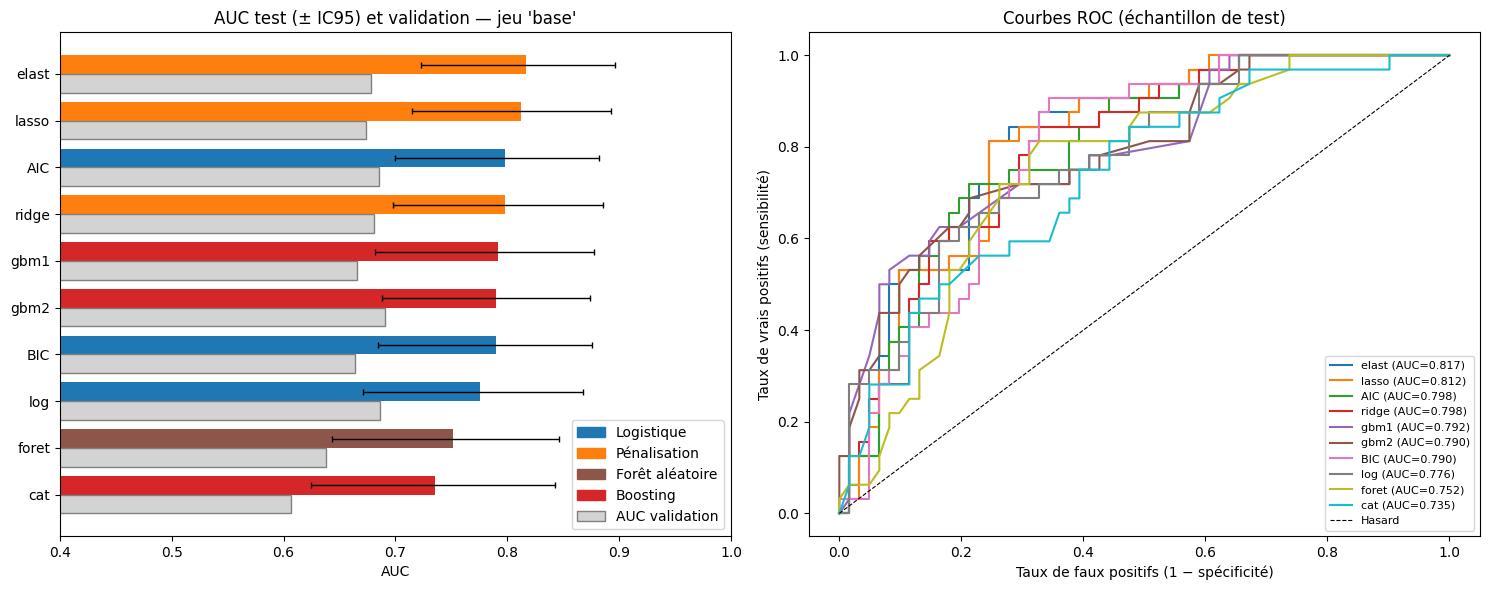

In [4]:
couleurs_famille = {"Logistique": "tab:blue", "Pénalisation": "tab:orange",
                    "Forêt aléatoire": "tab:brown", "Boosting": "tab:red"}
cmap = plt.get_cmap("tab10")

for jeu, r in resultats.items():
    t, y, pt = tableaux[jeu], r["Y_test"], r["pt"]
    pos = np.arange(len(t))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    ax1.barh(pos - 0.2, t["AUC_test"], height=0.4, color=[couleurs_famille[f] for f in t["Famille"]],
             xerr=[t["AUC_test"] - t["IC95_bas"], t["IC95_haut"] - t["AUC_test"]],
             error_kw=dict(ecolor="black", capsize=2, lw=1))
    ax1.barh(pos + 0.2, t["AUC_val"], height=0.4, color="lightgrey", edgecolor="grey")
    ax1.set_yticks(pos)
    ax1.set_yticklabels(t.index)
    ax1.invert_yaxis()
    ax1.set_xlim(0.4, 1.0)
    ax1.set_xlabel("AUC")
    ax1.set_title(f"AUC test (± IC95) et validation — jeu '{jeu}'")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs_famille.values()]
    handles.append(plt.Rectangle((0, 0), 1, 1, color="lightgrey", ec="grey"))
    ax1.legend(handles, list(couleurs_famille) + ["AUC validation"], loc="lower right")

    for k, m in enumerate(t.index):
        fpr, tpr, _ = sklm.roc_curve(y, pt[m])
        ax2.plot(fpr, tpr, color=cmap(k % 10), linewidth=1.5, label=f"{m} (AUC={t.loc[m, 'AUC_test']:.3f})")
    ax2.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Hasard")
    ax2.set_xlabel("Taux de faux positifs (1 − spécificité)")
    ax2.set_ylabel("Taux de vrais positifs (sensibilité)")
    ax2.set_title("Courbes ROC (échantillon de test)")
    ax2.legend(loc="lower right", fontsize=8)

    plt.tight_layout()
    plt.savefig(DOSSIER_SORTIE + f"resultats_CS_split_{jeu}.png", dpi=150)
    plt.show()

### 3.3 Hyperparamètres choisis et courbes de validation
Les courbes montrent le **log-loss de validation** en fonction du réglage : le minimum (point rouge) est le réglage retenu. Un minimum plat signifie que le réglage compte peu ; un minimum au bord de la grille signale qu'il faudrait l'élargir.


--- Jeu 'base' ---


,valeur retenue
nb_var_BIC,4.0000
nb_var_AIC,6.0000
C_ridge,0.0135
C_lasso,0.0808
C_elast,0.0487
nb_iter_gbm1,20.0000
nb_iter_gbm2,12.0000
nb_iter_cat,2.0000


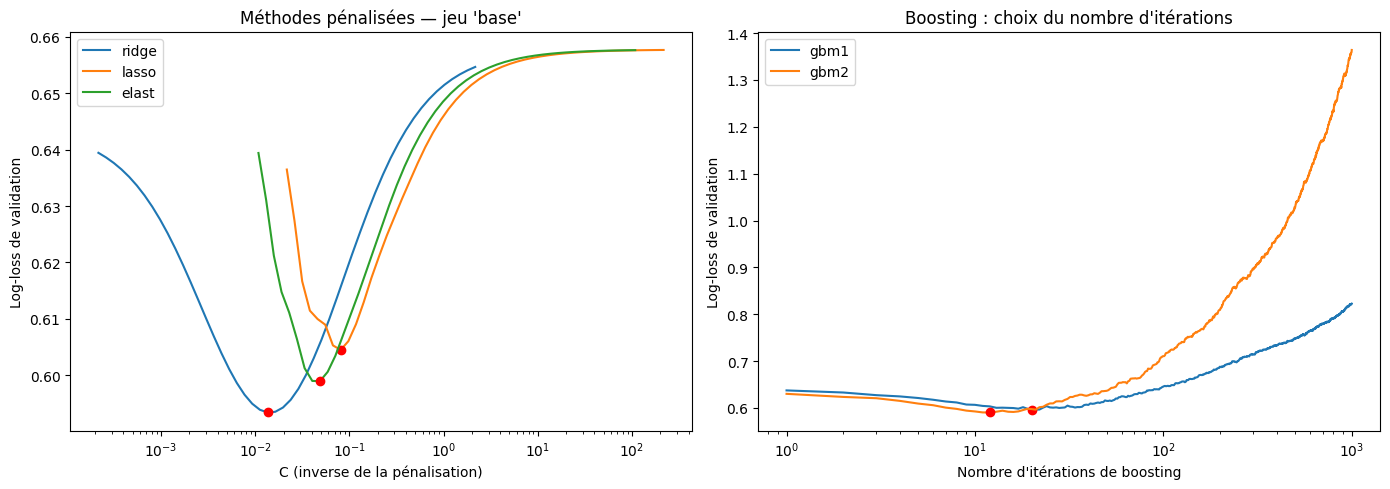

In [5]:
for jeu, r in resultats.items():
    print(f"\n--- Jeu '{jeu}' ---")
    display(pd.Series(r["hyper"], name="valeur retenue").to_frame().round(4))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for nom in ("ridge", "lasso", "elast"):
        Cs, err = r["courbes"][nom]
        ax1.plot(Cs, err, label=nom)
        ax1.plot(Cs[np.argmin(err)], err.min(), "o", color="red")
    ax1.set_xscale("log")
    ax1.set_xlabel("C (inverse de la pénalisation)")
    ax1.set_ylabel("Log-loss de validation")
    ax1.set_title(f"Méthodes pénalisées — jeu '{jeu}'")
    ax1.legend()

    for nom in ("gbm1", "gbm2"):
        it, err = r["courbes"][nom]
        ax2.plot(it, err, label=nom)
        ax2.plot(it[np.argmin(err)], err.min(), "o", color="red")
    ax2.set_xscale("log")
    ax2.set_xlabel("Nombre d'itérations de boosting")
    ax2.set_ylabel("Log-loss de validation")
    ax2.set_title("Boosting : choix du nombre d'itérations")
    ax2.legend()

    plt.tight_layout()
    plt.savefig(DOSSIER_SORTIE + f"resultats_CS_split_validation_{jeu}.png", dpi=150)
    plt.show()

## 4. Export des fichiers et synthèse
Les fichiers `PROB*_test.csv` (colonne `Y` puis une colonne de probabilités par méthode, calculées sur l'**échantillon de test**) sont lus par `03_analyseCS_complet.ipynb` avec `SUFFIXE_PROB = "_test"`.

In [6]:
for jeu, r in resultats.items():
    pd.concat([pd.Series(r["Y_test"], name="Y"), r["pt"]], axis=1).to_csv(DOSSIER_SORTIE + FICHIERS[jeu][1], index=False)

pd.concat({jeu: t for jeu, t in tableaux.items()}, names=["features", "methode"]).round(4).to_csv(
    DOSSIER_SORTIE + "metriques_CS_split.csv")
pd.concat({jeu: pd.Series(r["hyper"], name="valeur retenue") for jeu, r in resultats.items()},
          names=["features", "hyperparametre"]).to_csv(DOSSIER_SORTIE + "hyperparametres_CS_split.csv")

for jeu, t in tableaux.items():
    meilleur = t.index[0]
    print(f"Jeu '{jeu}' (apprentissage/validation/test = {resultats[jeu]['tailles']}) : meilleure méthode (AUC test) = "
          f"{meilleur} (AUC = {t.loc[meilleur, 'AUC_test']:.3f}, IC95 [{t.loc[meilleur, 'IC95_bas']:.3f} ; "
          f"{t.loc[meilleur, 'IC95_haut']:.3f}])")
    print("   Top 3 :", ", ".join(f"{m} ({t.loc[m, 'AUC_test']:.3f})" for m in t.index[:3]))

print("\nFichiers écrits :", ", ".join(FICHIERS[j][1] for j in JEUX),
      ", metriques_CS_split.csv, hyperparametres_CS_split.csv,", ", ".join(f"resultats_CS_split_{j}.png" for j in JEUX))

Jeu 'base' (apprentissage/validation/test = (276, 93, 93)) : meilleure méthode (AUC test) = elast (AUC = 0.817, IC95 [0.723 ; 0.896])
   Top 3 : elast (0.817), lasso (0.812), AIC (0.798)

Fichiers écrits : PROB_test.csv , metriques_CS_split.csv, hyperparametres_CS_split.csv, resultats_CS_split_base.png
